# Lab Assignment 5
Multiclass Classification using the Dermatology Dataset

## Setup

In [1]:
!pip -q install ucimlrepo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
from IPython.display import display

## Data Acquisition

In [3]:
dataset = fetch_ucirepo(id=33)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

target_name = y.columns[0]
df = pd.concat([X, y], axis=1)

df.head()

,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


## Summary Statistics

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

summary = X.agg(["mean", "median", "std", "min", "max"]).T
summary

Rows: 366
Columns: 35


,mean,median,std,min,max
erythema,2.068306,2.0,0.664753,0.0,3.0
scaling,1.795082,2.0,0.701527,0.0,3.0
definite-borders,1.549180,2.0,0.907525,0.0,3.0
itching,1.366120,1.0,1.138299,0.0,3.0
koebner phenomenon,0.633880,0.0,0.908016,0.0,3.0
polygonal papules,0.448087,0.0,0.957327,0.0,3.0
follicular papules,0.166667,0.0,0.570588,0.0,3.0
oral-mucosal involvement,0.377049,0.0,0.834147,0.0,3.0
knee elbow involvement,0.614754,0.0,0.982979,0.0,3.0
scalp involvement,0.519126,0.0,0.905639,0.0,3.0


## Missing Values and Duplicates

In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

clean_df = df.drop_duplicates().copy()

numeric_columns = X.columns.tolist()

for column in numeric_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

for column in numeric_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

print("Rows after duplicate removal:", len(clean_df))
print("Missing values after cleaning:", clean_df.isna().sum().sum())

Missing values: 8
Duplicate rows: 0
Rows after duplicate removal: 366
Missing values after cleaning: 0


## Outlier Handling

In [6]:
if "age" in clean_df.columns:
    q1 = clean_df["age"].quantile(0.25)
    q3 = clean_df["age"].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    clean_df["age"] = clean_df["age"].clip(lower, upper)

clean_df.describe()

,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,36.267760,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,15.156875,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,25.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,35.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,48.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,75.000000,6.000000


## Data Visualization

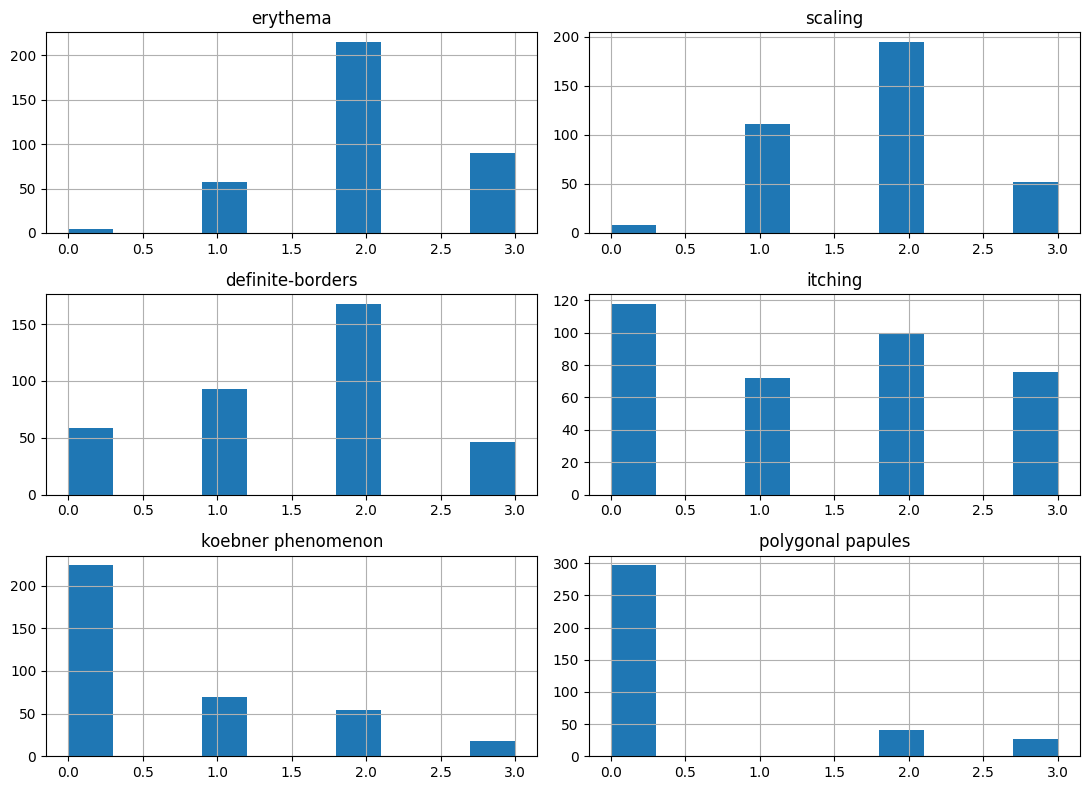

In [7]:
selected = numeric_columns[:6]

clean_df[selected].hist(
    figsize=(11, 8),
    bins=10
)

plt.tight_layout()
plt.show()

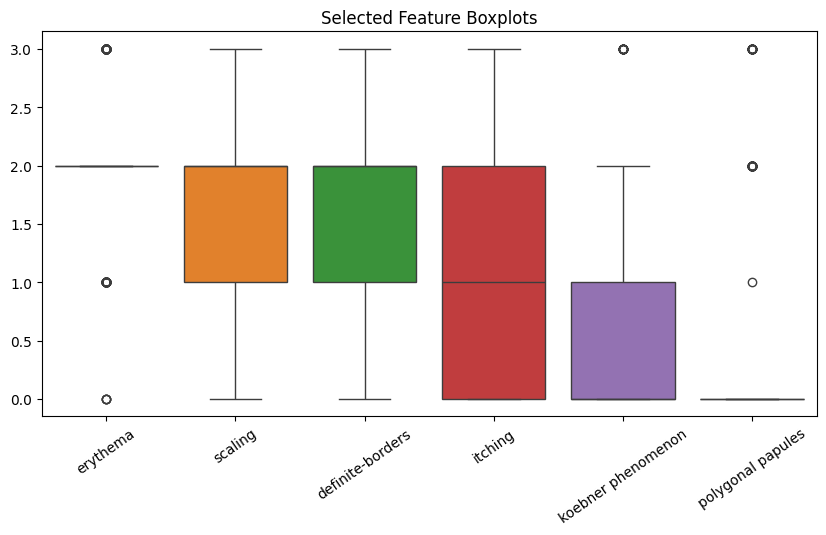

In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=clean_df[selected])
plt.xticks(rotation=35)
plt.title("Selected Feature Boxplots")
plt.show()

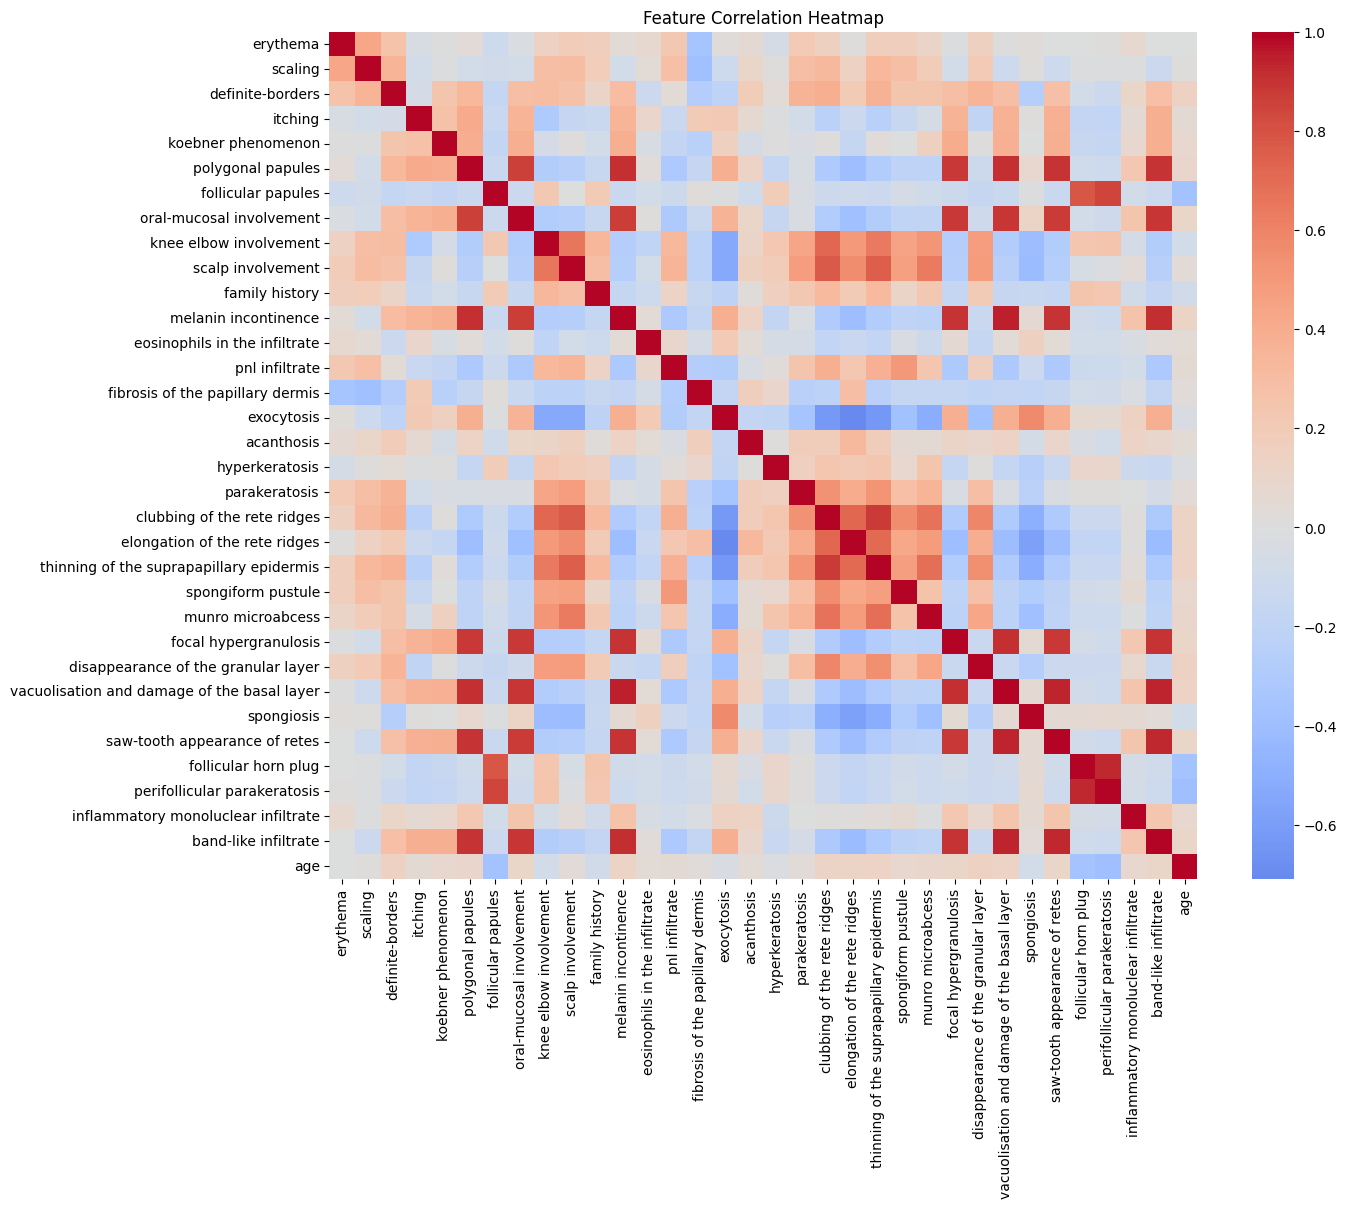

In [9]:
plt.figure(figsize=(14, 11))
sns.heatmap(
    clean_df[numeric_columns].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Heatmap")
plt.show()

## Class Distribution

,Class,Disease,Count,Percentage
0,1,Psoriasis,112,30.60
1,2,Seboreic Dermatitis,61,16.67
2,3,Lichen Planus,72,19.67
3,4,Pityriasis Rosea,49,13.39
4,5,Chronic Dermatitis,52,14.21
5,6,Pityriasis Rubra Pilaris,20,5.46


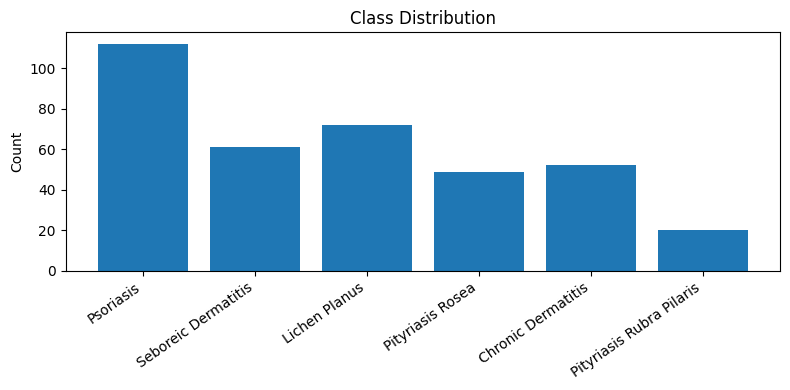

In [10]:
class_names = {
    1: "Psoriasis",
    2: "Seboreic Dermatitis",
    3: "Lichen Planus",
    4: "Pityriasis Rosea",
    5: "Chronic Dermatitis",
    6: "Pityriasis Rubra Pilaris"
}

raw_target = pd.to_numeric(
    clean_df[target_name],
    errors="coerce"
)

class_counts = raw_target.value_counts().sort_index()

distribution = pd.DataFrame({
    "Class": class_counts.index,
    "Disease": [
        class_names.get(int(value), str(value))
        for value in class_counts.index
    ],
    "Count": class_counts.values,
    "Percentage": (
        class_counts.values /
        class_counts.values.sum() * 100
    ).round(2)
})

display(distribution)

plt.figure(figsize=(8, 4))
plt.bar(
    distribution["Disease"],
    distribution["Count"]
)
plt.xticks(rotation=35, ha="right")
plt.ylabel("Count")
plt.title("Class Distribution")
plt.tight_layout()
plt.show()

The six classes are not perfectly balanced, so stratified sampling is used to preserve their proportions in the training and testing sets.

## Data Preprocessing

In [11]:
X = clean_df[numeric_columns]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(
    clean_df[target_name]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Classes:", label_encoder.classes_)

Training shape: (292, 34)
Testing shape: (74, 34)
Classes: [1 2 3 4 5 6]


## Model Training

In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
}

for model in models.values():
    model.fit(
        X_train_scaled,
        y_train
    )

print("Models trained:", list(models.keys()))

Models trained: ['Logistic Regression', 'KNN', 'Random Forest', 'SVM']


## Model Comparison

In [13]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    pred = model.predict(
        X_test_scaled
    )
    prob = model.predict_proba(
        X_test_scaled
    )

    predictions[name] = pred
    probabilities[name] = prob

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    auc = roc_auc_score(
        y_test,
        prob,
        multi_class="ovr",
        average="macro"
    )

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision,
        recall,
        f1,
        auc
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ]
)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.9595,0.9688,0.9595,0.9606,0.9991
1,KNN,0.9054,0.9193,0.9054,0.9081,0.9863
2,Random Forest,0.9595,0.9607,0.9595,0.9595,0.9983
3,SVM,0.9730,0.9775,0.9730,0.9730,0.9981


## Classification Reports

In [14]:
for name, pred in predictions.items():
    print(name)
    print(
        classification_report(
            y_test,
            pred,
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      0.83      0.91        12
           2       1.00      0.93      0.97        15
           3       0.77      1.00      0.87        10
           4       1.00      1.00      1.00        10
           5       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74

KNN
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        23
           1       0.80      0.67      0.73        12
           2       1.00      0.93      0.97        15
           3       0.64      0.90      0.75        10
           4       1.00      1.00      1.00        10
           5       1.00      1.00      1.00         4

    accuracy                           0.91        74

## Confusion Matrices

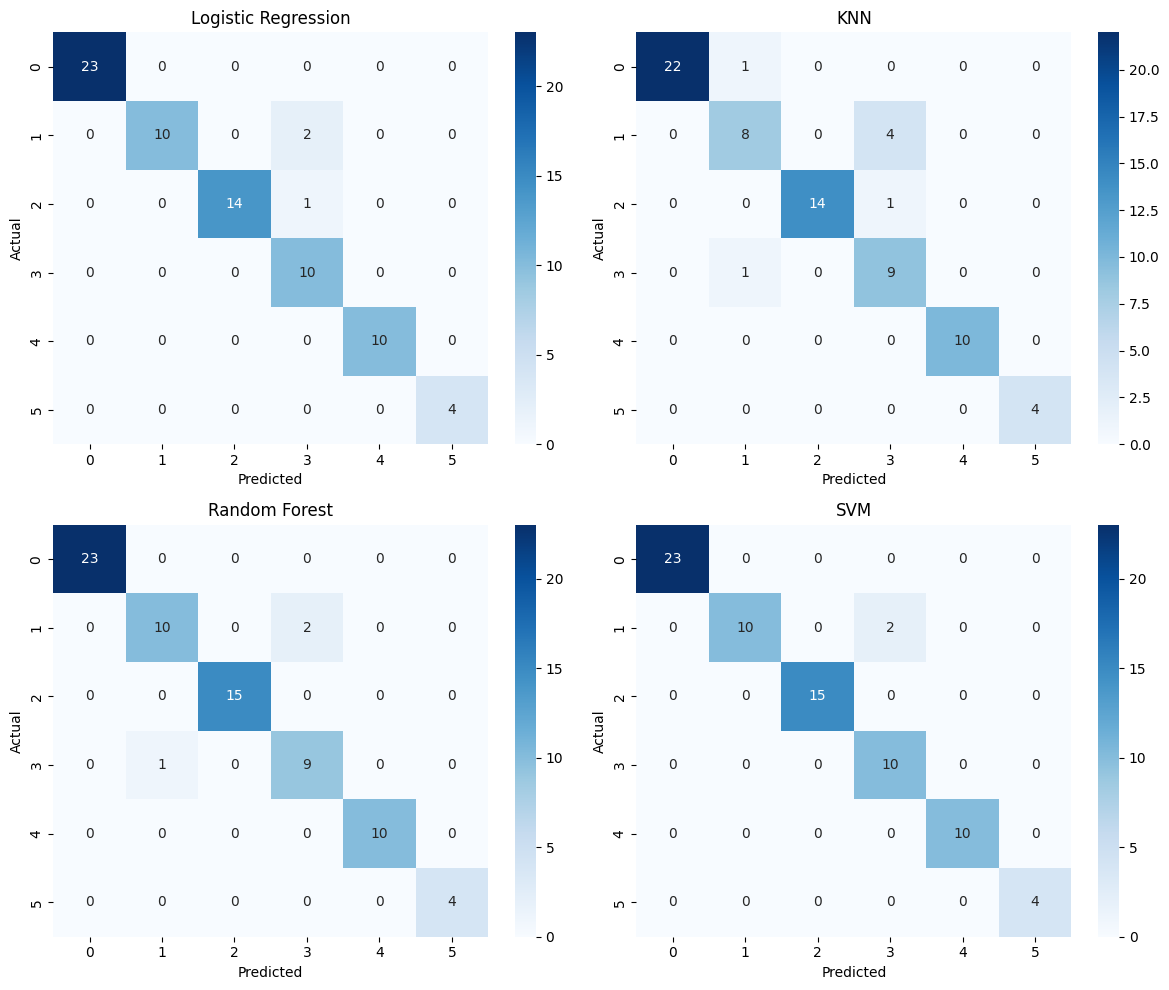

In [15]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

for ax, (name, pred) in zip(
    axes.ravel(),
    predictions.items()
):
    cm = confusion_matrix(
        y_test,
        pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Multiclass ROC Curves

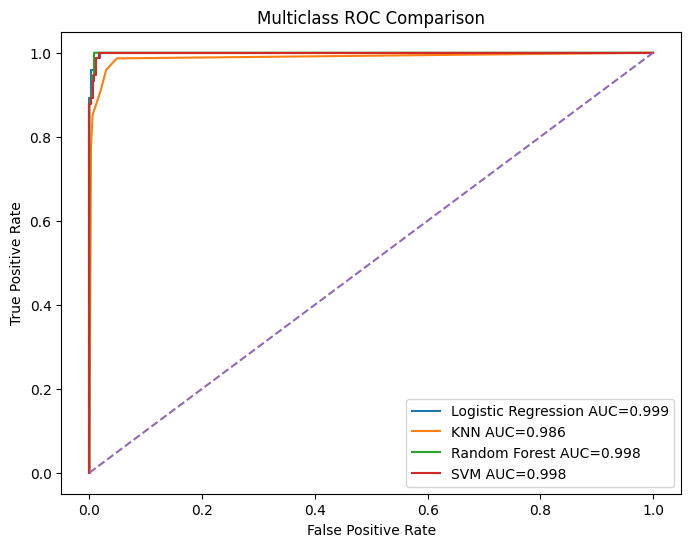

In [16]:
classes = np.arange(
    len(label_encoder.classes_)
)

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

plt.figure(figsize=(8, 6))

for name, prob in probabilities.items():
    fpr, tpr, thresholds = roc_curve(
        y_test_binary.ravel(),
        prob.ravel()
    )

    auc = roc_auc_score(
        y_test,
        prob,
        multi_class="ovr",
        average="macro"
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} AUC={auc:.3f}"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Comparison")
plt.legend()
plt.show()

## Result Interpretation

In [17]:
best_row = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("Highest test accuracy:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Macro ROC AUC:", round(best_row["ROC AUC"], 4))

Highest test accuracy: SVM
Accuracy: 0.973
Macro ROC AUC: 0.9981


Accuracy gives the overall proportion of correct predictions, while precision, recall and F1-score show how consistently the models handle the different disease classes. The confusion matrices show which classes are confused with each other, and ROC-AUC measures how well each model separates the classes across decision thresholds.

## Conclusion
The Dermatology dataset was cleaned, standardized and used for six-class classification. Logistic Regression, KNN, Random Forest and SVM were trained and compared using accuracy, precision, recall, F1-score, confusion matrices and multiclass ROC-AUC.